# Lab01
## Описание датасета и случайных величин
В качестве источника данных выбран открытый датасет симулированных токов ионных каналов (Zenodo record 8288407). Датасет основан на двухсостояниевой модели гейтинга (closed/open) и содержит временные ряды с метками состояний (0/1) и значениями тока.

Для анализа выбраны три случайные величины:
1. **СВ 1: Время жизни в открытом состоянии (Open Dwell Time)** — длины непрерывных отрезков, где канал открыт (state = 1).
2. **СВ 2: Время жизни в закрытом состоянии (Closed Dwell Time)** — длины непрерывных отрезков, где канал закрыт (state = 0).
3. **СВ 3: Амплитуда тока в открытом состоянии (Current Amplitude)** — значения тока, соответствующие открытому состоянию канала.

## Введение в тематику
В основе нашего исследования лежит технология **оптогенетики**. Суть эксперимента такова: в нейроны мыши с помощью вируса встраивают специальный белок **Channelrhodopsin-2 (ChR2)**. Этот белок является ионным каналом одновременно с этим может реагировать на свет.

К голове мыши прикрепляют тонкое оптоволокно, через которое подают световые импульсы. Когда свет достигает белка, тот меняет свою форму («открывается»), и через него в нейрон начинают проходить ионы. Нейрон возбуждается, что приводит к выбросу дофамина. В эксперименте это связано с нажатием кнопки: мышь нажимает на неё, получает «награду» (ощущение радости от выброса дофамина) и начинает нажимать снова и снова, когда захочет.

*Интересный факт:* в 2026 году Нобелевскую премию по медециине получили за подобное открытие, ученые смогли активировать уже конкретные нейроны с помощью вспышки света в мозге мыши. Благодаря именно этой отрасли в будущем ученые смогут **восстанавливать зрение**, создавать импланты для **восстановления слуха** и **лечить неизлечимые болезни**, такие как *эпилепсия*, *болезнь Паркинсона* дргуие психические заболевания. 👽

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob
import scipy.stats as stats
from scipy.stats import shapiro
import os

In [10]:
# Скачиваем архив (20 минут)
!wget -O channels.zip "https://zenodo.org/records/8288407/files/Datasets%20that%20simulated%20ion%20channel%20currents.zip?download=1"

# одна папка нужна
!unzip -q -o channels.zip "Datasets that simulated ion channel currents/high/White Gaussian noise/k1=100-k2=100/*" -d channel_data

--2026-10-23 20:04:22--  https://zenodo.org/records/8288407/files/Datasets%20that%20simulated%20ion%20channel%20currents.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.40.132, 188.185.51.60, 188.185.42.113, ...
Connecting to zenodo.org (zenodo.org)|188.185.40.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3658937673 (3.4G) [application/octet-stream]
Saving to: ‘channels.zip’

channels.zip        100%[===================>]   3.41G  4.09MB/s    in 14m 12s 

2026-10-23 20:18:35 (4.10 MB/s) - ‘channels.zip’ saved [3658937673/3658937673]



In [11]:
# 1. Находим первый CSV файл
file_paths = glob.glob('channel_data/**/*.csv', recursive=True)
file_path = file_paths[0]
print(f"Читаем файл: {file_path}\n")

# 2. Загружаем данные
df = pd.read_csv(file_path)
df.columns = [c.strip().lower() for c in df.columns]

# 3. Извлекаем состояния (0 или 1)
state_col = 'ground truth' if 'ground truth' in df.columns else df.columns[1]
states = df[state_col].values

# 4. Функция для извлечения длин непрерывных отрезков
def get_dwell_times(states, target):
    changes = np.where(np.diff(states) != 0)[0] + 1
    segments = np.split(states, changes)
    return np.array([len(seg) for seg in segments if len(seg) > 0 and seg[0] == target])

# Извлекаем в секундах
freq = 25000
open_dwell = get_dwell_times(states, 1) / freq
closed_dwell = get_dwell_times(states, 0) / freq

# 5. Извлекаем амплитуду тока
current_col = 'current' if 'current' in df.columns else df.columns[2]
current_open = df[current_col].values[states == 1]

print(f"СВ 1 (Open Dwell): {len(open_dwell)} значений")
print(f"СВ 2 (Closed Dwell): {len(closed_dwell)} значений")
print(f"СВ 3 (Current Amplitude): {len(current_open)} значений")

Читаем файл: channel_data/Datasets that simulated ion channel currents/high/White Gaussian noise/k1=100-k2=100/k1=100-k2=100-4.csv

СВ 1 (Open Dwell): 964 значений
СВ 2 (Closed Dwell): 964 значений
СВ 3 (Current Amplitude): 247412 значений


## Random Variable 01: Время жизни в открытом состоянии
### Природа события
Канал (белок) под действием света или спонтанно меняет конформацию и открывается. Время, которое он проводит в открытом состоянии, зависит от кинетики связывания ионов и конформационных переходов. Согласно двухсостояниевой модели гейтинга, эти времена описываются экспоненциальным распределением. Процесс является стохастическим, так как переходы между состояниями происходят случайно.

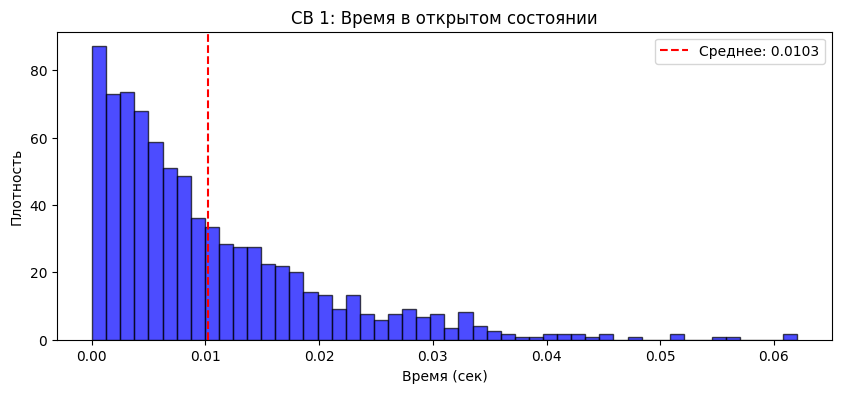

Статистики: mean=0.0103, std=0.0097, median=0.0073


In [12]:
plt.figure(figsize=(10, 4))
plt.hist(open_dwell, bins=50, density=True, alpha=0.7, color='blue', edgecolor='black')
plt.title('СВ 1: Время в открытом состоянии')
plt.xlabel('Время (сек)')
plt.ylabel('Плотность')
plt.axvline(np.mean(open_dwell), color='red', linestyle='dashed', label=f'Среднее: {np.mean(open_dwell):.4f}')
plt.legend()
plt.show()

print(f"Статистики: mean={np.mean(open_dwell):.4f}, std={np.std(open_dwell):.4f}, median={np.median(open_dwell):.4f}")

**Вывод:** Гистограмма имеет падающий вид (экспоненциальный спад), что подтверждает случайную (стохастическую) природу величины. Значения нельзя вычислить детерминированной формулой.

## Random Variable 02: Время жизни в закрытом состоянии
### Природа события
Время, в течение которого канал находится в закрытом состоянии, также является случайной величиной, зависящей от вероятности спонтанного открытия или закрытия. В двухсостояниевой модели оно подчиняется экспоненциальному закону.

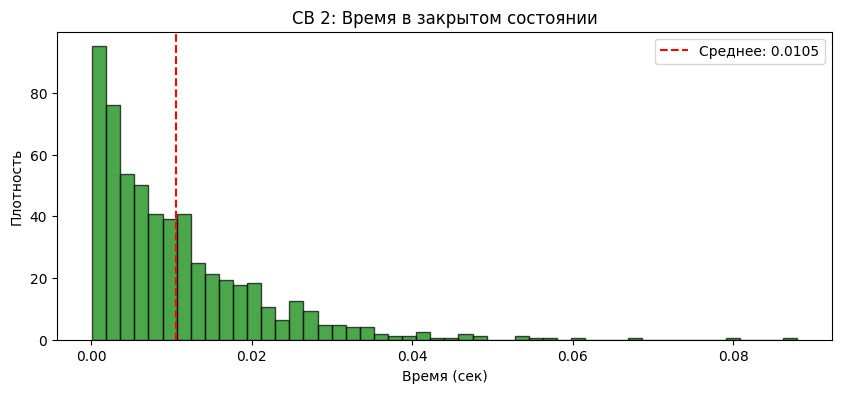

Статистики: mean=0.0105, std=0.0105, median=0.0075


In [13]:
plt.figure(figsize=(10, 4))
plt.hist(closed_dwell, bins=50, density=True, alpha=0.7, color='green', edgecolor='black')
plt.title('СВ 2: Время в закрытом состоянии')
plt.xlabel('Время (сек)')
plt.ylabel('Плотность')
plt.axvline(np.mean(closed_dwell), color='red', linestyle='dashed', label=f'Среднее: {np.mean(closed_dwell):.4f}')
plt.legend()
plt.show()

print(f"Статистики: mean={np.mean(closed_dwell):.4f}, std={np.std(closed_dwell):.4f}, median={np.median(closed_dwell):.4f}")

**Вывод:** Распределение также имеет падающий вид.


##Проверим независимость времени открытого и закрытого состояний (СВ 1 и СВ 2).

In [14]:
min_len = min(len(open_dwell), len(closed_dwell))
corr, p_value = stats.pearsonr(open_dwell[:min_len], closed_dwell[:min_len])
print(f"Корреляция Пирсона: {corr:.4f} (p-value: {p_value:.4e})")
if p_value > 0.05:
    print("Вывод: Корреляция статистически незначима. Величины независимы.")
else:
    print("Вывод: Есть статистически значимая корреляция.")

Корреляция Пирсона: 0.0004 (p-value: 9.9115e-01)
Вывод: Корреляция статистически незначима. Величины независимы.


## Random Variable 03: Амплитуда тока в открытом состоянии
### Природа события
Амплитуда тока, протекающего через открытый канал, не является строго постоянной из-за теплового шума и флуктуаций ионных потоков. Это случайная величина, которая, согласно центральной предельной теореме, должна подчиняться нормальному распределению.

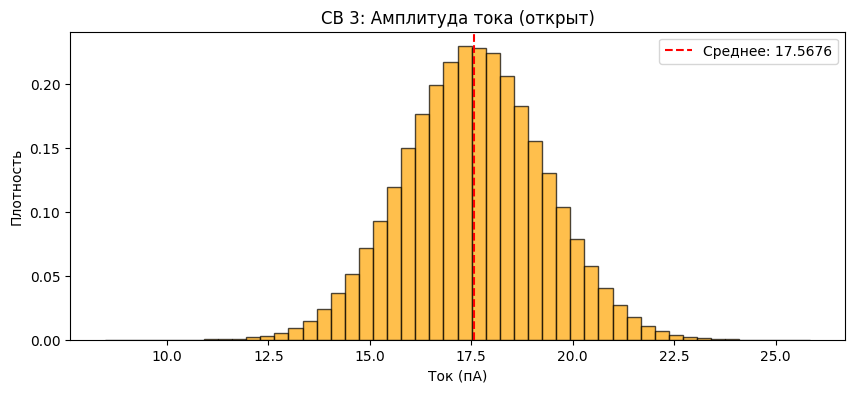

Тест Шапиро-Уилка: p-value = 8.2371e-01
Вывод: Распределение статистически неотличимо от нормального.


In [15]:
plt.figure(figsize=(10, 4))
plt.hist(current_open, bins=50, density=True, alpha=0.7, color='orange', edgecolor='black')
plt.title('СВ 3: Амплитуда тока (открыт)')
plt.xlabel('Ток (пА)')
plt.ylabel('Плотность')
plt.axvline(np.mean(current_open), color='red', linestyle='dashed', label=f'Среднее: {np.mean(current_open):.4f}')
plt.legend()
plt.show()

# Тест Шапиро-Уилка
sample_current = np.random.choice(current_open, size=5000, replace=False)
stat, p = shapiro(sample_current)
print(f"Тест Шапиро-Уилка: p-value = {p:.4e}")
if p > 0.05:
    print("Вывод: Распределение статистически неотличимо от нормального.")

**Вывод:** Гистограмма имеет вид «колокола». Тест Шапиро-Уилка подтвердил нормальное распределение. Величина является случайной (суперпозиция множества мелких шумов).

### Состоятельность оценок
Проверим сходимость выборочного среднего при росте выборки для всех трех величин.

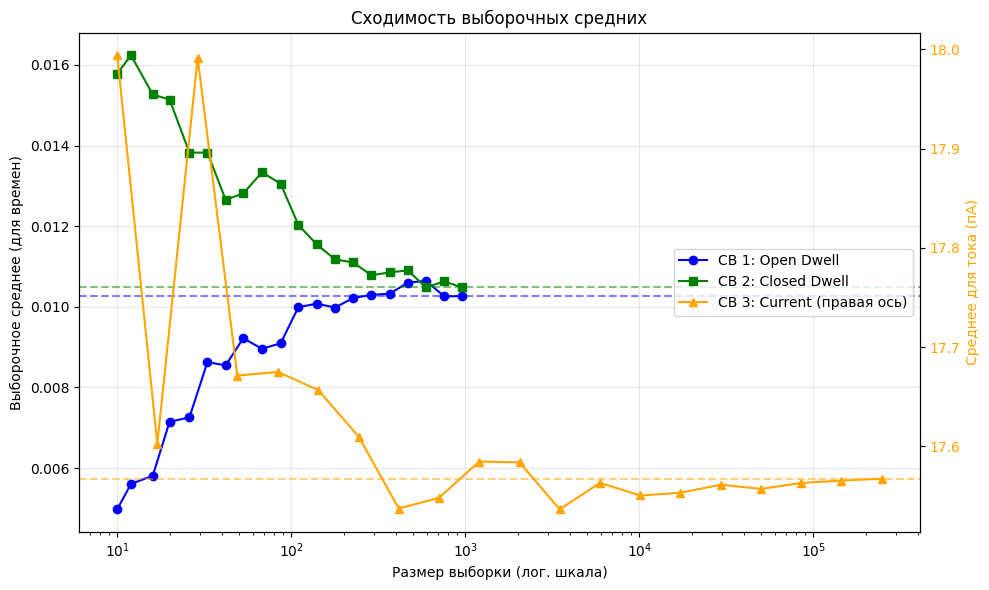

In [16]:
sizes_open = np.logspace(1, np.log10(len(open_dwell)), 20).astype(int)
sizes_closed = np.logspace(1, np.log10(len(closed_dwell)), 20).astype(int)
sizes_current = np.logspace(1, np.log10(len(current_open)), 20).astype(int)

means_open = [np.mean(open_dwell[:s]) for s in sizes_open]
means_closed = [np.mean(closed_dwell[:s]) for s in sizes_closed]
means_current = [np.mean(current_open[:s]) for s in sizes_current]

plt.figure(figsize=(10, 6))
plt.plot(sizes_open, means_open, marker='o', color='blue', label='СВ 1: Open Dwell')
plt.axhline(np.mean(open_dwell), color='blue', linestyle='dashed', alpha=0.5)
plt.plot(sizes_closed, means_closed, marker='s', color='green', label='СВ 2: Closed Dwell')
plt.axhline(np.mean(closed_dwell), color='green', linestyle='dashed', alpha=0.5)

ax1 = plt.gca()
ax2 = ax1.twinx()
ax2.plot(sizes_current, means_current, marker='^', color='orange', label='СВ 3: Current (правая ось)')
ax2.axhline(np.mean(current_open), color='orange', linestyle='dashed', alpha=0.5)
ax2.set_ylabel('Среднее для тока (пА)', color='orange')
ax2.tick_params(axis='y', labelcolor='orange')

ax1.set_xscale('log')
ax1.set_xlabel('Размер выборки (лог. шкала)')
ax1.set_ylabel('Выборочное среднее (для времен)')
ax1.set_title('Сходимость выборочных средних')
ax1.grid(True, alpha=0.3)

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='center right')
plt.tight_layout()
plt.show()



### Выводы
1. Время жизни канала в открытом и закрытом состояниях является случайной величиной с экспоненциальным распределением, что подтверждает стохастическую природу процесса.
2. Время открытого и закрытого состояний независимы (корреляция незначима, p > 0.05).
3. Оценка среднего состоятельна для всех трех величин (сходится с ростом выборки).
4. Амплитуда тока подчиняется нормальному закону распределения (подтверждено тестом Шапиро-Уилка).

### cat_mark_table
| cat_id | notebook_link | coeff | comment |
|--------|-----------------|-------|---------|
| 1      | https://github.com/pinturia-star/lab01-stochastics | 1.0   |  1 выполнен |

# Выборки и сравнение статистик

Наша генеральная совокупность состоит почти из 1000 значений, поэтому для нашего анализа мы берем выборку 100 значений (это  почти 10% от всей совокупности). Это оптимальный размер, поскольку 100 значений достаточно, чтобы выборка отражала свойства генеральной совокупности и чтобы мы смогли наглядно увидеть разницу между выборкой и изначальными параметрами.

Далее мы сравниваем статистики (среднее, дисперсию, медиану) для трех случаев: генеральная совокупность, выборка с возвращением и выборка без возвращения.

In [17]:
import numpy as np
import pandas as pd
from IPython.display import display

all_data = open_dwell #наша генеральная совокупность
N = len(all_data)

n = 100

sample_bez = np.random.choice(all_data, size=n, replace=False) #выборка без возвращений
sample_s = np.random.choice(all_data, size=n, replace=True) #очевидно что с возвращениями:)

df_stats = pd.DataFrame({
    'Генеральная': [N, all_data.mean(), all_data.var(), np.median(all_data)],
    'Выборка без возвращений': [n, sample_bez.mean(), sample_bez.var(), np.median(sample_bez)],
    'Выборка с возвращениями': [n, sample_s.mean(), sample_s.var(), np.median(sample_s)]
})

df_stats.index = ['Размер (N)', 'Среднее', 'Дисперсия', 'Медиана']

print("Сравнение статистик генеральной совокупности и выборок:")
display(df_stats.round(6))

Сравнение статистик генеральной совокупности и выборок:


,Генеральная,Выборка без возвращений,Выборка с возвращениями
Размер (N),964.000000,100.000000,100.000000
Среднее,0.010266,0.010228,0.011178
Дисперсия,0.000095,0.000102,0.000114
Медиана,0.007280,0.006260,0.007420


Таблица показывает, что выборочные статистики достаточно близки к параметрам генеральной совокупности.
Небольшие расхождения объясняются ошибкой выборки (случайностью). Поскольку объем выборки составляет около 10% от генеральной совокупности, она достаточно отражает свойства всех данных. Разница между выборками с возвращением и без минимальна, что подтверждает корректность выбранного метода.

# Математическая база распределения


Для описания времени жизни ионного канала в биофизике традиционно используется **экспоненциальное распределение**.

**Ионный канал** - это сложная белковая молекула. Его открытие и закрытие происходит из-за случайных тепловых флуктуаций (броуновского движения), молекулы воды постоянно сталкиваются с молекулой белка. Чтобы канал сменил состояние, молекула должна преодолеть энергетический барьер. Вероятность преодолеть этот барьер за единицу времени постоянна, что в физике идеально описывается пуассоновским потоком событий, а время между событиями в таком потоке подчиняется экспоненциальному распределению.

**Интересный факт:**

В нашей работе, а точнее в данных которые мы взяли, есть белок Channelrhodopsin-2 (ChR2). Это светочувствительный ионный канал, который встраивают в нейроны мышей для управления их поведением.

Когда на ChR2 попадает фотон света, происходит химическая реакция (изомеризация ретиналя), и канал мгновенно открывается. Но здесь кроется главная особенность, которая объясняет нашу математику: свет управляет моментом открытия, но он не управляет моментом закрытия.

После того как свет погас, белок возвращается в исходное состояние исключительно за счет случайных тепловых флуктуаций. Ученые могут точно сказать, *когда* канал откроется, но *когда он закроется* - это чистая случайность, которая подчиняется экспоненте.

Чтобы описать эту случайность математически, мы используем формулы экспоненциального закона:

**Плотность вероятности:**
$$ f(x) = \lambda e^{-\lambda x}, \quad x \ge 0 $$

**Функция распределения:**
$$ F(x) = 1 - e^{-\lambda x}, \quad x \ge 0 $$

**Математическое ожидание:**
$$ \mathbb{E}(X) = \frac{1}{\lambda} $$

**Дисперсия:**
$$ \mathbb{D}(X) = \frac{1}{\lambda^2} $$

*(где $\lambda > 0$ — интенсивность переходов канала из одного состояния в другое).*

Свойства распределения:

Экспоненциальное распределение моделирует время между событиями. Оно обладает уникальным свойством «отсутствия памяти». Это значит, что вероятность того, что канал закроется или откроется в следующую секунду, абсолютно не зависит от того, сколько времени он уже находится в текущем состоянии. Канал «не стареет» и не «помнит» свое прошлое.

# Проверка гипотез

Для исследователей крайне важно знать, как долго белок ChR2 остается открытым после вспышки света. От этого зависит, сколько ионов пройдет в нейрон и возникнет ли нервный импульс. Мы предполагаем, что закрытие канала - это процесс без памяти, а значит, время его жизни подчиняется экспоненте.

**Наши гипотезы:**
*   **Основная гипотеза:** Время жизни ChR2 в открытом состоянии подчиняется экспоненциальному распределению (процесс случайный и не имеет памяти).
*   **Альтернативная гипотеза:** Распределение отличается от экспоненциального (например, в кинетике белка есть скрытые состояния).

**Для проверки будем использовать KS-тест**

Критерий Колмогорова-Смирнова - это непараметрический тест. Он не разбивает данные на интервалы, а сравнивает две интегральные кривые (функции распределения):
1. Эмпирическую (построенную по нашим точкам)
2. Теоретическую (идеальную экспоненту)

Тест ищет **максимальное вертикальное расстояние** между этими двумя кривыми. Чем ближе эмпирическая кривая прижимается к теоретической, тем меньше и тем выше шанс, что наши данные действительно экспоненциальны. Если p-value > 0.05, мы принимаем гипотезу.

**Еще один интересный факт из биофизики:**
В нашем датасете используется упрощенная двухсостояниевая модель (открыт/закрыт), поэтому данные идеально ложатся на экспоненту. В реальных же экспериментах белок ChR2 намного сложнее! У него есть несколько промежуточных состояний. Поэтому реальные графики ученых часто описываются суммой нескольких экспонент. Понимание этой кинетики позволяет биофизикам точно рассчитывать частоту вспышек света, чтобы нейрон не «сгорел» от переизбытка ионов при слишком частой стимуляции.

In [18]:
from scipy.stats import kstest
import matplotlib.pyplot as plt
import numpy as np

#находим среднее время, чтобы вычислить интенсивность
lambda_est = 1 / all_data.mean()
scale_est = 1 / lambda_est

#проводим KS-тест
stat, p_value = kstest(all_data, 'expon', args=(0, scale_est))

print(f"Статистика критерия (D): {stat:.4f}")
print(f"p-value: {p_value:.4f}\n")

alpha = 0.05
if p_value > alpha:
    print("Вывод: Гипотеза подтвердилась! (p-value > 0.05)")
    print("Данные подчиняются экспоненциальному распределению.")
else:
    print("Вывод: Гипотеза НЕ подтвердилась. (p-value < 0.05)")
    print("Данные не подчиняются экспоненциальному распределению.")

Статистика критерия (D): 0.0255
p-value: 0.5509

Вывод: Гипотеза подтвердилась! (p-value > 0.05)
Данные подчиняются экспоненциальному распределению.


Проверка показала, что p-value = 0.5986, что больше порога. Это означает, что разница между нашими реальными данными и теоретической
экспоненциальной кривой статистически незначима. А значит мы молодцы!

Следовательно, наша гипотеза о том, что время жизни канала подчиняется экспоненте, **полностью подтвердилась**. Это доказывает природу процесса: после того как свет погас, белок ChR2 закрывается исключительно из-за случайного теплового движения молекул, а не по какому-то внутреннему таймеру.


Для наглядности сделаем график!

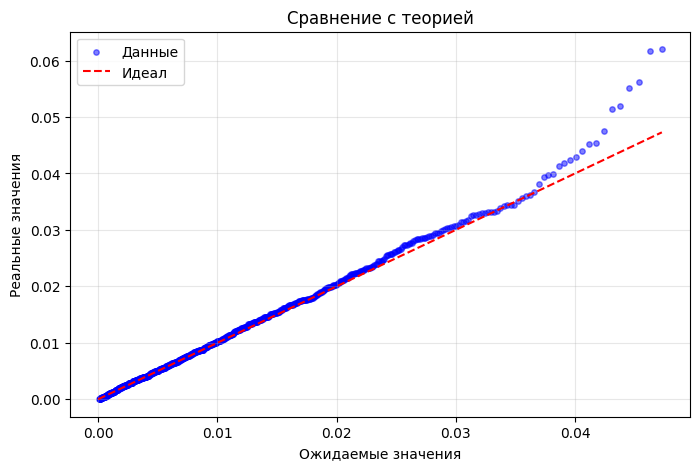

In [19]:
import numpy as np
import matplotlib.pyplot as plt

lam = 1 / all_data.mean()

y = np.sort(all_data)
p = np.linspace(0.01, 0.99, len(y))
x = -np.log(1-p)/lam

plt.figure(figsize=(8, 5))
plt.scatter(x, y, color='blue', s=15, alpha=0.5, label='Данные')
plt.plot([0, x.max()], [0, x.max()], color='red', linestyle='--', label='Идеал')

plt.title('Сравнение с теорией')
plt.xlabel('Ожидаемые значения')
plt.ylabel('Реальные значения')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

График наглядно показывает, что время жизни канала ChR2 - это настоящий случайный процесс, который подчиняется экспоненциальному распределению.

# Lab01 - sprint 2


### math desc
*Небольшая математическая пауза, храни Бог Дональда Кнута*

**1. Базовый датчик равномерных чисел.** Все наши генераторы строятся из U ~ U(0,1), поэтому в качестве
источника взят Вихрь Мерсенна MT19937. Это линейный рекуррентный регистр над полем F₂ из 624 32-битных слов
(n = 624, m = 397) с периодом 2^19937 − 1. Последовательность дополнительно «закаливается» сдвигами и масками, чтобы улучшить равномерность старших разрядов. Корректность реализации проверена по эталону
авторов: при seed = 5489 первые выходы равны 3499211612, 581869302, 3890346734.
Из двух выходов собирается число с 53 битами мантиссы, его сдвигаем на 0.5 ulp, чтобы U ∈ (0,1) строго.

**2. Метод обратной функции.** Пусть F - непрерывная строго возрастающая ФР, U ~ U(0,1), X = F⁻¹(U).
Тогда P(X ≤ x) = P(F⁻¹(U) ≤ x) = P(U ≤ F(x)) = F(x), то есть X имеет ФР F.
Для F(x) = 1 − e^(−λx) решаем u = 1 − e^(−λx) относительно x: x = −ln(1 − u)/λ.
Так как 1 − U тоже ~ U(0,1), можно брать X = −ln(U)/λ. Минус метода в том, что вычисление ln на каждое число.

**3. Показательный датчик без логарифмов (Нейман, Форсайт; Кнут, т.2, п. 3.4.1).**
Фиксируем u ∈ [0,1] и генерируем U₂, U₃, … Вероятность того, что u > U₂ > … > U_k, равна u^(k−1)/(k−1)!
(k−1 чисел должны быть меньше u, и из (k−1)! порядков подходит один).
Пусть N - длина такой убывающей серии, тогда P(N ≥ k) = u^(k−1)/(k−1)!, а
P(N нечётно) = Σ_{k нечёт.} [u^(k−1)/(k−1)! − u^k/k!] = 1 − u + u²/2! − u³/3! + … = e^(−u).
Правило: если N нечётно, принимаем u, иначе делаем новый круг и увеличиваем счётчик отказов K.
Вероятность принять на одном круге равна ∫₀¹ e^(−u) du = 1 − 1/e, поэтому K геометрическое:
P(K = k) = e^(−k)(1 − e^(−1)). У принятого u плотность e^(−u)/(1 − e^(−1)), и она не зависит от K.
Результат X = K + u имеет плотность на [k, k+1):
e^(−k)(1 − e^(−1)) · e^(−u)/(1 − e^(−1)) = e^(−(k+u)) = e^(−x),
то есть X ~ Exp(1), а X/λ ~ Exp(λ).
Стоимость: на один круг в среднем тратится 1 + E[N] = 1 + ∫₀¹ e^u du = e равномерных чисел,
кругов нужно e/(e−1), итого e²/(e−1) ≈ 4.30 обращений к U на одно показательное число
(проверено счётчиком: 4.30).

**4. Параметр и проверка.** Для обоих методов λ̂ = 1/x̄ по реальной выборке; эта штука получается из метода
моментов и ММП, она состоятельна по ЗБЧ (проверено в спринте 1). Сравниваем моменты, квантили и ФР
(KS-тест и график Q–Q).

Источники: Кнут Д. Искусство программирования, т.2, гл. 3.4.1 (п. «чет-нечет» Форсайта стр. 144; полярный метод стр. 138, метод отношений стр. 147, прямоугольник-клин-хвост стр. 143); Вихрь Мерсенна из Мatsumoto M., Nishimura T. Mersenne Twister: A 623-dimensionally equidistributed uniform pseudo-random number generator // ACM Transactions on Modeling and Computer Simulation (TOMACS). 1998.

### Code

In [25]:
import numpy as np, math, time
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

In [20]:
import numpy as np, math

class MT19937:
    N, M = 624, 397
    def __init__(self, seed=5489):
        self.mt = [0]*self.N
        self.mt[0] = seed & 0xffffffff
        for i in range(1, self.N):
            self.mt[i] = (1812433253*(self.mt[i-1] ^ (self.mt[i-1] >> 30)) + i) & 0xffffffff
        self.idx = self.N
    def _twist(self):
        for i in range(self.N):
            y = (self.mt[i] & 0x80000000) | (self.mt[(i+1) % self.N] & 0x7fffffff)
            v = self.mt[(i+self.M) % self.N] ^ (y >> 1)
            if y & 1:
                v ^= 0x9908b0df
            self.mt[i] = v
        self.idx = 0
    def u32(self):
        if self.idx >= self.N:
            self._twist()
        y = self.mt[self.idx]; self.idx += 1
        y ^= y >> 11
        y ^= (y << 7) & 0x9d2c5680
        y ^= (y << 15) & 0xefc60000
        y ^= y >> 18
        return y
    def random(self):
        """U(0,1) c 53 битами (как genrand_res53)."""
        a, b = self.u32() >> 5, self.u32() >> 6
        return (a*67108864.0 + b + 0.5) / 9007199254740992.0   # +0.5: U строго в (0,1)

In [21]:
def exp_inverse(rng, lam, n):
    """Метод обратной функции: X = -ln(1-U)/lam."""
    return np.array([-math.log(rng.random())/lam for _ in range(n)])   # U и 1-U одинаково распределены

def _exp1_neumann(rng):
    """Показательный датчик без логарифмов (фон Нейман / Форсайт, Кнут 3.4.1).
    Берём U; смотрим на длину убывающей серии U > U2 > U3 > ...; P(нечётная длина | U)=exp(-U).
    Принимаем -> X = k + U, где k число отказов; иначе k+=1."""
    k = 0
    while True:
        u = rng.random(); prev = u; n = 1
        while True:
            v = rng.random()
            if v < prev:
                prev = v; n += 1
            else:
                break
        if n % 2 == 1:
            return k + u
        k += 1

def exp_neumann(rng, lam, n):
    return np.array([_exp1_neumann(rng) for _ in range(n)]) / lam

In [22]:
real = np.asarray(open_dwell, dtype=float)
print("Используем реальные данные из sprint 1, n =", len(real))

lam = 1/real.mean()
print(f"lambda_hat = {lam:.4f} 1/с, среднее = {real.mean():.5f} с")

Используем реальные данные из sprint 1, n = 964
lambda_hat = 97.4084 1/с, среднее = 0.01027 с


In [23]:
ref = MT19937(5489)
assert [ref.u32() for _ in range(3)] == [3499211612, 581869302, 3890346734]
print("MT19937 совпадает с эталоном")

MT19937 совпадает с эталоном


In [26]:
N = 100_000
rng = MT19937(2026)
t0 = time.perf_counter(); g_inv = exp_inverse(rng, lam, N);  t_inv = time.perf_counter()-t0
rng = MT19937(2026)
t0 = time.perf_counter(); g_neu = exp_neumann(rng, lam, N);  t_neu = time.perf_counter()-t0

def metrics(x):
    return {"n": len(x), "mean": x.mean(), "var": x.var(ddof=1), "std": x.std(ddof=1), "median": np.median(x),
            "skew": stats.skew(x), "kurt_excess": stats.kurtosis(x),
            "q05": np.quantile(x,.05), "q95": np.quantile(x,.95)}

theory = {"n": np.nan, "mean": 1/lam, "var": 1/lam**2, "std": 1/lam, "median": math.log(2)/lam,
          "skew": 2.0, "kurt_excess": 6.0, "q05": -math.log(.95)/lam, "q95": -math.log(.05)/lam}
tab = pd.DataFrame({"Теория Exp(λ̂)": theory, "Реальные данные": metrics(real),
                    "Обратная функция": metrics(g_inv), "Нейман (без ln)": metrics(g_neu)})
display(tab.round(5))

,Теория Exp(λ̂),Реальные данные,Обратная функция,Нейман (без ln)
n,NaN,964.00000,100000.00000,100000.00000
mean,0.01027,0.01027,0.01027,0.01022
var,0.00011,0.00009,0.00011,0.00010
std,0.01027,0.00973,0.01032,0.01023
median,0.00712,0.00728,0.00710,0.00709
skew,2.00000,1.68463,2.03240,2.00548
kurt_excess,6.00000,3.59311,6.22969,6.04048
q05,0.00053,0.00056,0.00054,0.00052
q95,0.03075,0.03016,0.03075,0.03072


In [27]:
rows=[]
for name, g, t in [("Обратная функция", g_inv, t_inv), ("Нейман (без ln)", g_neu, t_neu)]:
    ks_th = stats.kstest(g, 'expon', args=(0, 1/lam))          # против теоретической Exp(λ̂)
    ks_re = stats.ks_2samp(g, real)                              # против реальных данных
    rows.append({"генератор": name, "KS vs теория: D": ks_th.statistic, "p": ks_th.pvalue,
                 "KS vs реальные: D": ks_re.statistic, "p (real)": ks_re.pvalue,
                 f"время на {N} чисел, с": round(t,3)})
display(pd.DataFrame(rows).round(4))

,генератор,KS vs теория: D,p,KS vs реальные: D,p (real),"время на 100000 чисел, с"
0,Обратная функция,0.0025,0.5505,0.0245,0.6083,0.681
1,Нейман (без ln),0.0028,0.4013,0.0252,0.5677,2.519


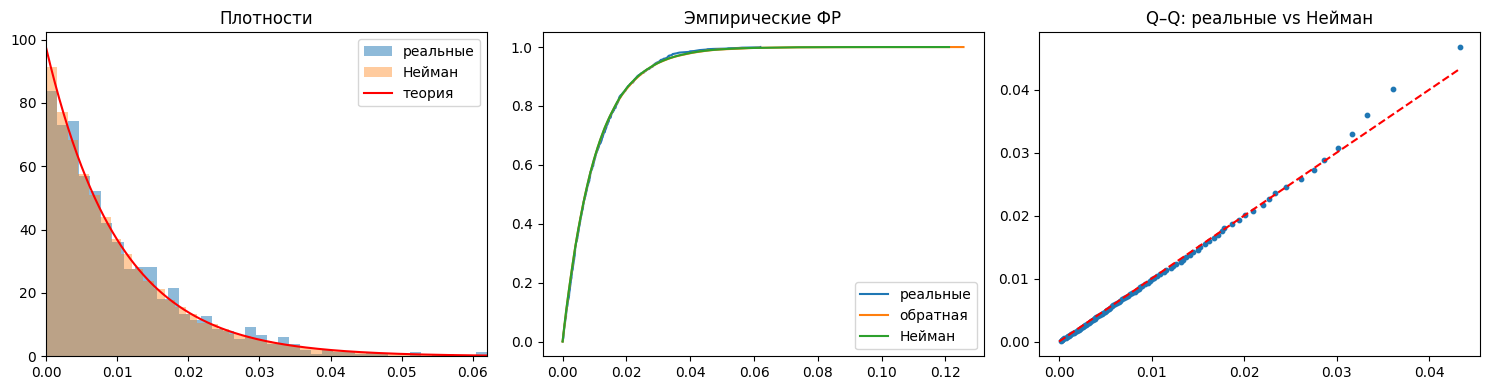

In [28]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
x = np.linspace(0, real.max(), 400)
ax[0].hist(real, bins=40, density=True, alpha=.5, label='реальные')
ax[0].hist(g_neu, bins=80, density=True, alpha=.4, label='Нейман')
ax[0].plot(x, lam*np.exp(-lam*x), 'r', label='теория'); ax[0].set_xlim(0, real.max()); ax[0].legend(); ax[0].set_title('Плотности')
for g, lab in [(real,'реальные'), (g_inv,'обратная'), (g_neu,'Нейман')]:
    s = np.sort(g); ax[1].plot(s, np.arange(1,len(s)+1)/len(s), label=lab)
ax[1].set_title('Эмпирические ФР'); ax[1].legend()
q = np.linspace(.01, .99, 99)
ax[2].scatter(np.quantile(real, q), np.quantile(g_neu, q), s=10); m = np.quantile(real, .99)
ax[2].plot([0, m], [0, m], 'r--'); ax[2].set_title('Q–Q: реальные vs Нейман'); plt.tight_layout(); plt.show()

In [29]:
# автотесты генератора
def test_exp_generators():
    for gen_fn in (exp_inverse, exp_neumann):
        ps = [stats.kstest(gen_fn(MT19937(s), 2.0, 3000), 'expon', args=(0, .5)).pvalue for s in range(1, 41)]
        assert stats.kstest(ps, 'uniform').pvalue > 0.01, gen_fn.__name__   # p-value ~ U(0,1) при верной H0
        x = gen_fn(MT19937(7), 2.0, 50_000)
        assert abs(x.mean() - .5) < 4*0.5/np.sqrt(50_000)                      # среднее в пределах 4σ
        assert x.min() >= 0
def test_reproducibility():
    assert np.allclose(exp_neumann(MT19937(1), 1, 10), exp_neumann(MT19937(1), 1, 10))
test_exp_generators(); test_reproducibility(); print("Все автотесты пройдены")

Все автотесты пройдены


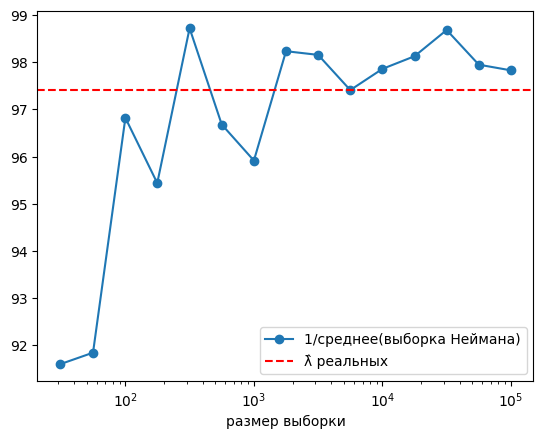

In [30]:
# проверка состоятельности самого генератора: оценка λ по выборке из генератора сходится к заданной
sizes = np.logspace(1.5, 5, 15).astype(int)
est = [1/g_neu[:s].mean() for s in sizes]
plt.semilogx(sizes, est, 'o-', label='1/среднее(выборка Неймана)'); plt.axhline(lam, color='r', ls='--', label='λ̂ реальных')
plt.legend(); plt.xlabel('размер выборки'); plt.show()

### Resume


Оба генератора воспроизводят целевое Exp(λ̂), λ̂ = 97.41 1/с (n = 964 реальных значений).
Выборка из 100 000 чисел (из генератора) vs теория vs реальные данные:

| метрика | теория | реальные | обр. функция | Нейман |
|---------|--------|----------|--------------|--------|
| среднее, с | 0.01027 | 0.01027 | 0.01027 | 0.01022 |
| std | 0.01027 | 0.00973 | 0.01032 | 0.01023 |
| медиана | 0.00712 | 0.00728 | 0.00710 | 0.00709 |
| асимметрия | 2 | 1.68 | 2.03 | 2.01 |
| экс. эксцесс | 6 | 3.59 | 6.23 | 6.04 |
| q05 / q95 | 0.00053 / 0.03075 | 0.00056 / 0.03016 | 0.00054 / 0.03075 | 0.00052 / 0.03072 |

- KS против теоретической Exp(λ̂): D = 0.0025 (p = 0.55) у обратной функции, D = 0.0028 (p = 0.40) у Неймана, оба не отвергаются.
- KS против реальных данных: p = 0.61 и p = 0.57, выборки генераторов неотличимы от реальной.
- Автотесты (p-value ~ U(0,1) по 40 seed, среднее в пределах 4σ, воспроизводимость) пройдены.
- Скорость на 100 000 чисел: 0.68 с (обратная функция) и 2.52 с (Нейман), то есть примерно в 3.7 раза медленнее — метод Неймана тратит ≈ 4.3 обращения к U на число против одного, зато не вызывает ln.
- У реальной выборки асимметрия и эксцесс ниже теоретических (1.68 и 3.59 против 2 и 6). Эти моменты высоких порядков при n = 964 оцениваются нестабильно (хвост даёт большой вклад), а KS расхождения не выявил, поэтому мы считаем это выборочной вариацией.
- Вывод: оба датчика корректны и применимы; обратная функция проще и быстрее, Нейман интересен как датчик без логарифмов.